In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ROOT = Path(r"D:\Upenn\Large-scaleML\result")

DISEASES = {
    "cihd_pmbb": "CIHD",
    "ckd_pmbb": "CKD",
    "hypothyroidism_pmbb": "Hypothyroidism",
    "t2d_pmbb": "T2D",
}
MODELS = {
    "clmbr-t-base":   {"label": "CLMBR-T-base",   "n_layers": 12, "color": "#2a78d6"},
    "gatortron-base": {"label": "GatorTron-base", "n_layers": 24, "color": "#eb6834"},
    "gatortronS":     {"label": "GatorTronS",     "n_layers": 24, "color": "#1baf7a"},
}
CONDITIONS = {
    "text_no_race":   {"label": "without race", "ls": "-",  "hollow": False},
    "text_with_race": {"label": "with race",    "ls": "--", "hollow": True},
}
METRICS = [("race_auroc", "Race probe AUROC"),
           ("race_bal_acc", "Race probe balanced accuracy")]

X_BASE, X_CLS = 0.0, 1.3
JITTER = {"clmbr-t-base": -0.025, "gatortron-base": 0.0, "gatortronS": 0.025}
BASE_COLOR = "#5f5e58"

# Race Probe

In [2]:
frames = []
for dfolder, dlabel in DISEASES.items():
    for m in MODELS:
        p = pd.read_csv(ROOT / dfolder / m / "probes" / "probe_metrics.csv")
        p = p[["condition", "rep", "race_auroc", "race_bal_acc"]].copy()
        p["disease"] = dlabel
        p["model"] = m
        frames.append(p)

df = pd.concat(frames, ignore_index=True)
df.head()

,condition,rep,race_auroc,race_bal_acc,disease,model
0,text_with_race,last_L3,0.999876,0.997339,CIHD,clmbr-t-base
1,text_with_race,last_L6,0.999954,0.997309,CIHD,clmbr-t-base
2,text_with_race,last_L9,0.999995,0.999362,CIHD,clmbr-t-base
3,text_with_race,last_L12,1.000000,0.999924,CIHD,clmbr-t-base
4,text_with_race,mean_L3,1.000000,1.000000,CIHD,clmbr-t-base


In [ ]:
parts = df["rep"].str.extract(r"^(mean|last)_L(\d+)$")
df["pool"] = parts[0]
df["layer"] = pd.to_numeric(parts[1])
df["n_layers"] = df["model"].map({m: v["n_layers"] for m, v in MODELS.items()})
df["depth"] = df["layer"] / df["n_layers"]

df["kind"] = "other"                                                     # CLMBR last_L3/6/9 are not plotted
df.loc[df["rep"] == "baseline_onehot", "kind"] = "baseline"
df.loc[df["pool"] == "mean", "kind"] = "mean"
df.loc[df["rep"] == "cls_last", "kind"] = "cls"                          # GatorTron [CLS]
df.loc[(df["pool"] == "last") & (df["layer"] == df["n_layers"]), "kind"] = "cls"   # CLMBR final-layer last token

df["x"] = np.nan
df.loc[df["kind"] == "baseline", "x"] = X_BASE
df.loc[df["kind"] == "mean", "x"] = df.loc[df["kind"] == "mean", "depth"]
df.loc[df["kind"] == "cls", "x"] = X_CLS
mask = df["kind"].isin(["mean", "cls"])
df.loc[mask, "x"] = df.loc[mask, "x"] + df.loc[mask, "model"].map(JITTER)

plot_df = df[df["kind"] != "other"].copy()

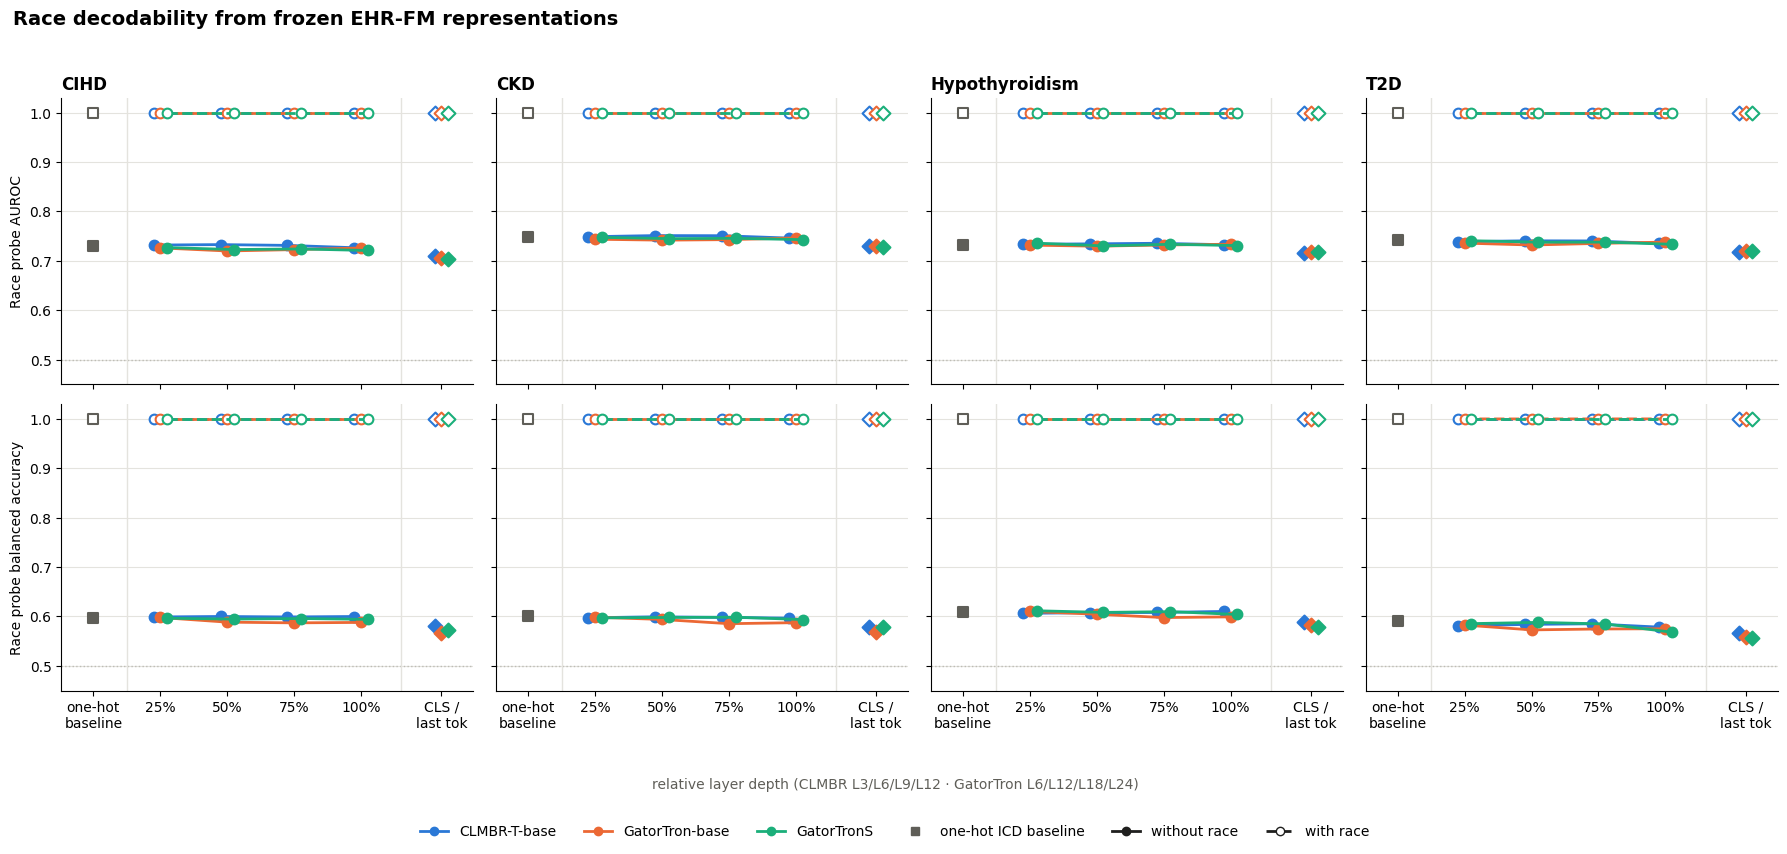

In [4]:
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})
diseases = list(DISEASES.values())
fig, axes = plt.subplots(len(METRICS), len(diseases), figsize=(18, 8.5),
                         sharex=True, sharey=True)

for r, (metric, mlabel) in enumerate(METRICS):
    for c, dis in enumerate(diseases):
        ax = axes[r, c]
        sub = plot_df[plot_df["disease"] == dis]

        for cond, cs in CONDITIONS.items():
            sc = sub[sub["condition"] == cond]

            b = sc[sc["kind"] == "baseline"].iloc[0]
            ax.scatter(X_BASE, b[metric], marker="s", s=60,
                       facecolors="white" if cs["hollow"] else BASE_COLOR,
                       edgecolors=BASE_COLOR, linewidths=1.5, zorder=4)

            for m, ms in MODELS.items():
                line = sc[(sc["model"] == m) & (sc["kind"] == "mean")].sort_values("x")
                ax.plot(line["x"], line[metric], ls=cs["ls"], lw=2, color=ms["color"],
                        marker="o", ms=7, mec=ms["color"], mew=1.5,
                        mfc="white" if cs["hollow"] else ms["color"], zorder=3)

                cls = sc[(sc["model"] == m) & (sc["kind"] == "cls")]
                ax.scatter(cls["x"], cls[metric], marker="D", s=50,
                           facecolors="white" if cs["hollow"] else ms["color"],
                           edgecolors=ms["color"], linewidths=1.5, zorder=3)

        ax.axhline(0.5, color="#bdbcb5", lw=1, ls=":")
        for xv in [0.125, 1.15]:
            ax.axvline(xv, color="#e4e3de", lw=1)
        ax.grid(axis="y", color="#e4e3de", lw=0.8)
        ax.set_axisbelow(True)
        for s in ["top", "right"]:
            ax.spines[s].set_visible(False)

        ax.set_xlim(-0.12, 1.42)
        ax.set_ylim(0.45, 1.03)
        ax.set_xticks([X_BASE, 0.25, 0.5, 0.75, 1.0, X_CLS],
                      ["one-hot\nbaseline", "25%", "50%", "75%", "100%", "CLS /\nlast tok"])
        if r == 0:
            ax.set_title(dis, loc="left", fontsize=12, fontweight="bold")
        if c == 0:
            ax.set_ylabel(mlabel)

handles = (
    [Line2D([], [], color=ms["color"], lw=2, marker="o", label=ms["label"]) for ms in MODELS.values()]
    + [Line2D([], [], color=BASE_COLOR, marker="s", ls="", label="one-hot ICD baseline")]
    + [Line2D([], [], color="#1f1f1e", lw=2, ls=cs["ls"], marker="o",
              mfc="white" if cs["hollow"] else "#1f1f1e", label=cs["label"])
       for cs in CONDITIONS.values()]
)
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False,
           bbox_to_anchor=(0.5, -0.01))
fig.supxlabel("relative layer depth (CLMBR L3/L6/L9/L12 · GatorTron L6/L12/L18/L24)",
              y=0.06, fontsize=10, color="#5f5e58")
fig.suptitle("Race decodability from frozen EHR-FM representations",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout(rect=(0, 0.08, 1, 0.96))

plt.show()

# Outcome Probe (overall)

In [3]:
frames = []
for dfolder, dlabel in DISEASES.items():
    for m in MODELS:
        p = pd.read_csv(ROOT / dfolder / m / "probes" / "probe_metrics.csv")
        p = p.rename(columns={"ckd_auroc": "outcome_auroc",
                              "ckd_auprc": "outcome_auprc"})
        p = p[["outcome", "condition", "rep", "outcome_auroc", "outcome_auprc",
               "auroc_gap_b_minus_w"]].copy()
        p["disease"] = dlabel
        p["model"] = m
        frames.append(p)

df_out = pd.concat(frames, ignore_index=True)
print(df_out.groupby("disease")["outcome"].unique()) 
df_out.head()

disease
CIHD                        [cihd]
CKD                          [ckd]
Hypothyroidism    [hypothyroidism]
T2D                          [t2d]
Name: outcome, dtype: object


,outcome,condition,rep,outcome_auroc,outcome_auprc,auroc_gap_b_minus_w,disease,model
0,cihd,text_with_race,last_L3,0.577486,0.027832,0.026363,CIHD,clmbr-t-base
1,cihd,text_with_race,last_L6,0.670199,0.036995,0.028814,CIHD,clmbr-t-base
2,cihd,text_with_race,last_L9,0.699164,0.043067,0.014413,CIHD,clmbr-t-base
3,cihd,text_with_race,last_L12,0.712271,0.047271,0.015169,CIHD,clmbr-t-base
4,cihd,text_with_race,mean_L3,0.680879,0.041364,0.015212,CIHD,clmbr-t-base


In [4]:
parts = df_out["rep"].str.extract(r"^(mean|last)_L(\d+)$")
df_out["pool"] = parts[0]
df_out["layer"] = pd.to_numeric(parts[1])
df_out["n_layers"] = df_out["model"].map({m: v["n_layers"] for m, v in MODELS.items()})
df_out["depth"] = df_out["layer"] / df_out["n_layers"]

df_out["kind"] = "other"
df_out.loc[df_out["rep"] == "baseline_onehot", "kind"] = "baseline"
df_out.loc[df_out["pool"] == "mean", "kind"] = "mean"
df_out.loc[df_out["rep"] == "cls_last", "kind"] = "cls"
df_out.loc[(df_out["pool"] == "last") & (df_out["layer"] == df_out["n_layers"]), "kind"] = "cls"

df_out["x"] = np.nan
df_out.loc[df_out["kind"] == "baseline", "x"] = X_BASE
df_out.loc[df_out["kind"] == "mean", "x"] = df_out.loc[df_out["kind"] == "mean", "depth"]
df_out.loc[df_out["kind"] == "cls", "x"] = X_CLS
mask = df_out["kind"].isin(["mean", "cls"])
df_out.loc[mask, "x"] = df_out.loc[mask, "x"] + df_out.loc[mask, "model"].map(JITTER)

plot_out = df_out[df_out["kind"] != "other"].copy()

# sanity check: one-hot baseline identical across models?
print(plot_out[plot_out["kind"] == "baseline"]
      .pivot_table(index=["disease", "condition"], columns="model", values="outcome_auroc"))

model                          clmbr-t-base  gatortron-base  gatortronS
disease        condition                                               
CIHD           text_no_race        0.688348        0.688348    0.688348
               text_with_race      0.688116        0.688116    0.688116
CKD            text_no_race        0.642751        0.642751    0.642751
               text_with_race      0.664798        0.664798    0.664798
Hypothyroidism text_no_race        0.595991        0.595991    0.595991
               text_with_race      0.614490        0.614490    0.614490
T2D            text_no_race        0.548494        0.548494    0.548494
               text_with_race      0.604255        0.604255    0.604255


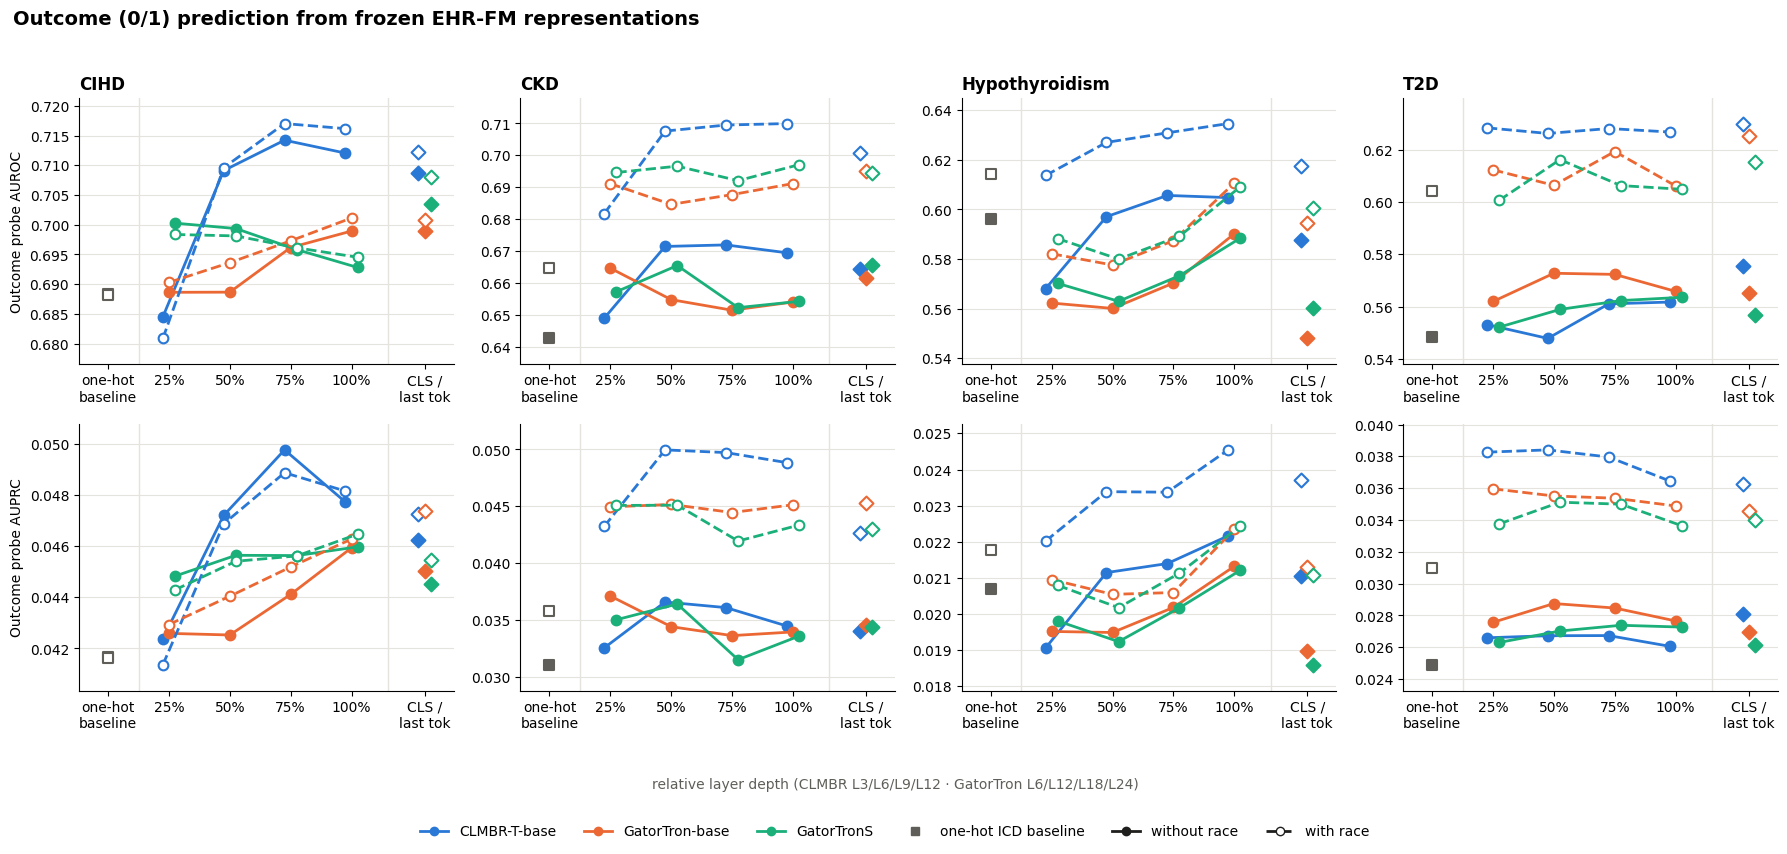

In [10]:
OUT_METRICS = [
    ("outcome_auroc", "Outcome probe AUROC", 0.5),     # (column, y label, chance line or None)
    ("outcome_auprc", "Outcome probe AUPRC", None),
]

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})
diseases = list(DISEASES.values())
fig, axes = plt.subplots(len(OUT_METRICS), len(diseases), figsize=(18, 8.5),
                         sharex=False, sharey=False)

for r, (metric, mlabel, chance) in enumerate(OUT_METRICS):
    for c, dis in enumerate(diseases):
        ax = axes[r, c]
        sub = plot_out[plot_out["disease"] == dis]

        for cond, cs in CONDITIONS.items():
            sc = sub[sub["condition"] == cond]

            b = sc[sc["kind"] == "baseline"].iloc[0]
            ax.scatter(X_BASE, b[metric], marker="s", s=60,
                       facecolors="white" if cs["hollow"] else BASE_COLOR,
                       edgecolors=BASE_COLOR, linewidths=1.5, zorder=4)

            for m, ms in MODELS.items():
                line = sc[(sc["model"] == m) & (sc["kind"] == "mean")].sort_values("x")
                ax.plot(line["x"], line[metric], ls=cs["ls"], lw=2, color=ms["color"],
                        marker="o", ms=7, mec=ms["color"], mew=1.5,
                        mfc="white" if cs["hollow"] else ms["color"], zorder=3)

                cls = sc[(sc["model"] == m) & (sc["kind"] == "cls")]
                ax.scatter(cls["x"], cls[metric], marker="D", s=50,
                           facecolors="white" if cs["hollow"] else ms["color"],
                           edgecolors=ms["color"], linewidths=1.5, zorder=3)

        vals = sub[metric].dropna()
        pad = (vals.max() - vals.min()) * 0.12
        lo, hi = vals.min() - pad, vals.max() + pad
        ax.set_ylim(lo, hi)
        if chance is not None and lo < chance < hi:
            ax.axhline(chance, color="#bdbcb5", lw=1, ls=":")

        for xv in [0.125, 1.15]:
            ax.axvline(xv, color="#e4e3de", lw=1)
        ax.grid(axis="y", color="#e4e3de", lw=0.8)
        ax.set_axisbelow(True)
        for s in ["top", "right"]:
            ax.spines[s].set_visible(False)

        ax.set_xlim(-0.12, 1.42)
        ax.set_xticks([X_BASE, 0.25, 0.5, 0.75, 1.0, X_CLS],
                      ["one-hot\nbaseline", "25%", "50%", "75%", "100%", "CLS /\nlast tok"])
        if r == 0:
            ax.set_title(dis, loc="left", fontsize=12, fontweight="bold")
        if c == 0:
            ax.set_ylabel(mlabel)

handles = (
    [Line2D([], [], color=ms["color"], lw=2, marker="o", label=ms["label"]) for ms in MODELS.values()]
    + [Line2D([], [], color=BASE_COLOR, marker="s", ls="", label="one-hot ICD baseline")]
    + [Line2D([], [], color="#1f1f1e", lw=2, ls=cs["ls"], marker="o",
              mfc="white" if cs["hollow"] else "#1f1f1e", label=cs["label"])
       for cs in CONDITIONS.values()]
)
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False,
           bbox_to_anchor=(0.5, -0.01))
fig.supxlabel("relative layer depth (CLMBR L3/L6/L9/L12 · GatorTron L6/L12/L18/L24)",
              y=0.06, fontsize=10, color="#5f5e58")
fig.suptitle("Outcome (0/1) prediction from frozen EHR-FM representations",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout(rect=(0, 0.08, 1, 0.96))
plt.show()

# Outcome Probe (stratified by race)

In [14]:
CLS_REP = {"clmbr-t-base": "last_L12", "gatortron-base": "cls_last", "gatortronS": "cls_last"}
GAP, GAP_LO, GAP_HI = "tpr_gap_b_minus_w", "tpr_gap_ci_lo", "tpr_gap_ci_hi"

rows = []
for dfolder, dlabel in DISEASES.items():
    for m in MODELS:
        p = pd.read_csv(ROOT / dfolder / m / "probes" / "ckd_fdr_by_race.csv")   # same filename in every disease folder
        p = p[p["rep"] == CLS_REP[m]][["condition", "alert_rate", GAP, GAP_LO, GAP_HI]].copy()
        p["disease"] = dlabel
        p["model"] = m
        rows.append(p)

tpr_gap = pd.concat(rows, ignore_index=True)
ALERT_RATES = sorted(tpr_gap["alert_rate"].unique())
tpr_gap.pivot_table(index=["alert_rate", "disease", "condition"], columns="model", values=GAP).round(3)

model                                     clmbr-t-base  gatortron-base  \
alert_rate disease        condition                                      
0.05       CIHD           text_no_race          -0.114          -0.097   
                          text_with_race        -0.072          -0.053   
           CKD            text_no_race          -0.092          -0.073   
                          text_with_race         0.124           0.236   
           Hypothyroidism text_no_race          -0.031          -0.035   
                          text_with_race        -0.155          -0.139   
           T2D            text_no_race          -0.066          -0.063   
                          text_with_race         0.230           0.235   
0.10       CIHD           text_no_race          -0.086          -0.102   
                          text_with_race        -0.086          -0.099   
           CKD            text_no_race          -0.144          -0.096   
                          text_with_race         0.204           0.320   
           Hypothyroidism text_no_race          -0.052          -0.080   
                          text_with_race        -0.224          -0.197   
           T2D            text_no_race          -0.092          -0.096   
                          text_with_race         0.390           0.413   
0.20       CIHD           text_no_race          -0.149          -0.160   
                          text_with_race        -0.122          -0.089   
           CKD            text_no_race          -0.149          -0.111   
                          text_with_race         0.246           0.385   
           Hypothyroidism text_no_race          -0.031          -0.134   
                          text_with_race        -0.320          -0.308   
           T2D            text_no_race          -0.145          -0.120   
                          text_with_race         0.480           0.551   

model                                     gatortronS  
alert_rate disease        condition                   
0.05       CIHD           text_no_race        -0.067  
                          text_with_race      -0.018  
           CKD            text_no_race        -0.095  
                          text_with_race       0.218  
           Hypothyroidism text_no_race        -0.014  
                          text_with_race      -0.109  
           T2D            text_no_race        -0.083  
                          text_with_race       0.253  
0.10       CIHD           text_no_race        -0.029  
                          text_with_race      -0.037  
           CKD            text_no_race        -0.086  
                          text_with_race       0.282  
           Hypothyroidism text_no_race        -0.013  
                          text_with_race      -0.209  
           T2D            text_no_race        -0.058  
                          text_with_race       0.377  
0.20       CIHD           text_no_race        -0.108  
                          text_with_race      -0.061  
           CKD            text_no_race        -0.084  
                          text_with_race       0.361  
           Hypothyroidism text_no_race         0.017  
                          text_with_race      -0.366  
           T2D            text_no_race        -0.092  
                          text_with_race       0.491

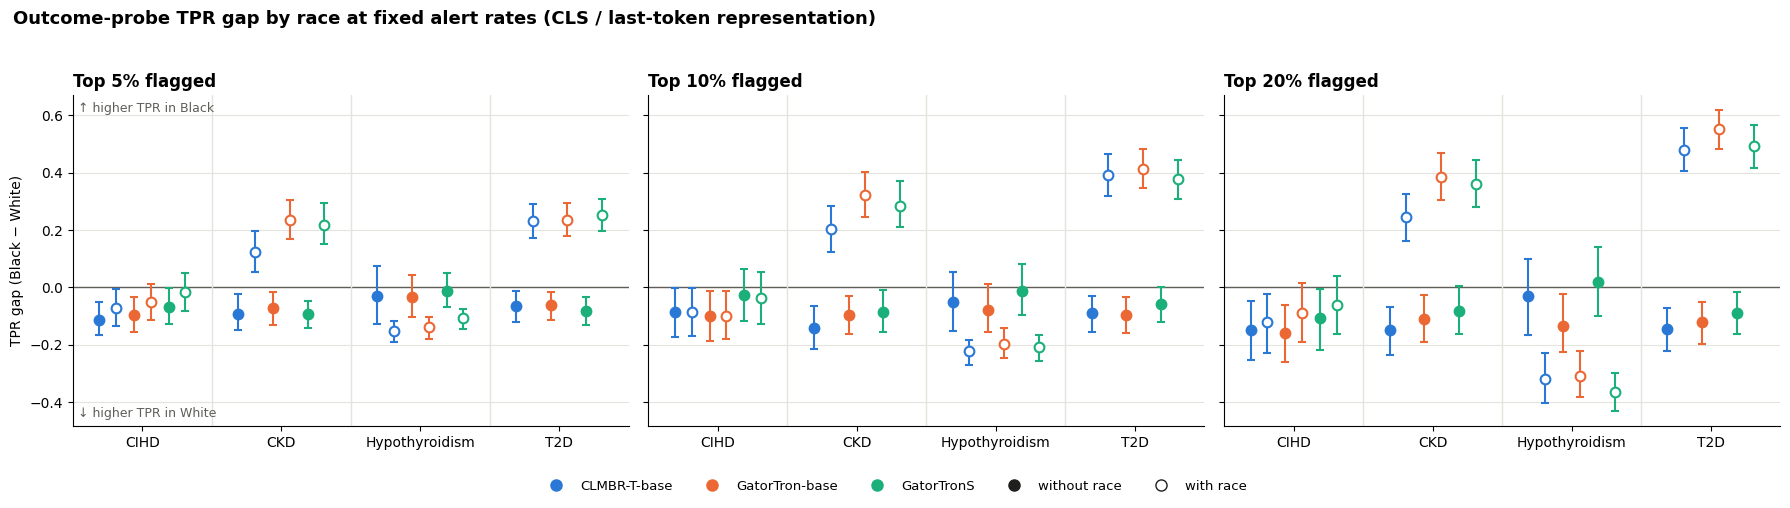

In [15]:
diseases = list(DISEASES.values())
x = np.arange(len(diseases))
MODEL_OFF = {"clmbr-t-base": -0.25, "gatortron-base": 0.0, "gatortronS": 0.25}
COND_OFF = {"text_no_race": -0.06, "text_with_race": 0.06}

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})
fig, axes = plt.subplots(1, len(ALERT_RATES), figsize=(6 * len(ALERT_RATES), 5), sharey=True)

for ax, ar in zip(axes, ALERT_RATES):
    for m, ms in MODELS.items():
        for cond, cs in CONDITIONS.items():
            g = (tpr_gap[(tpr_gap["model"] == m) & (tpr_gap["condition"] == cond)
                         & (tpr_gap["alert_rate"] == ar)]
                 .set_index("disease").reindex(diseases))
            xpos = x + MODEL_OFF[m] + COND_OFF[cond]
            yerr = np.vstack([g[GAP] - g[GAP_LO], g[GAP_HI] - g[GAP]])
            ax.errorbar(xpos, g[GAP], yerr=yerr, fmt="o", ms=7,
                        color=ms["color"], mec=ms["color"], mew=1.5,
                        mfc="white" if cs["hollow"] else ms["color"],
                        elinewidth=1.5, capsize=3, zorder=3)

    ax.axhline(0, color="#5f5e58", lw=1)
    for xv in x[:-1] + 0.5:
        ax.axvline(xv, color="#e4e3de", lw=1)
    ax.grid(axis="y", color="#e4e3de", lw=0.8)
    ax.set_axisbelow(True)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)

    ax.set_xticks(x, diseases)
    ax.set_xlim(-0.5, len(diseases) - 0.5)
    ax.set_title(f"Top {ar:.0%} flagged", loc="left", fontsize=12, fontweight="bold")

axes[0].set_ylabel("TPR gap (Black − White)")
axes[0].text(0.01, 0.98, "↑ higher TPR in Black", transform=axes[0].transAxes,
             ha="left", va="top", fontsize=9, color="#5f5e58")
axes[0].text(0.01, 0.02, "↓ higher TPR in White", transform=axes[0].transAxes,
             ha="left", va="bottom", fontsize=9, color="#5f5e58")

handles = (
    [Line2D([], [], color=ms["color"], marker="o", ls="", ms=8, label=ms["label"])
     for ms in MODELS.values()]
    + [Line2D([], [], color="#1f1f1e", marker="o", ls="", ms=8,
              mfc="white" if cs["hollow"] else "#1f1f1e", label=cs["label"])
       for cs in CONDITIONS.values()]
)
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False,
           bbox_to_anchor=(0.5, -0.01), fontsize=9.5)
fig.suptitle("Outcome-probe TPR gap by race at fixed alert rates (CLS / last-token representation)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0.07, 1, 0.95))
plt.show()